In [1]:
import numpy as np
import pandas as pd
df = pd.read_csv("EVSalesMarket.csv")
df

,Vehicle_ID,Sale_Date,Manufacturer,Model,Vehicle_Type,Market_Segment,Fuel_Type,Battery_Capacity_kWh,Driving_Range_km,Vehicle_Price_INR,EV_Sales_Units,State,City,Charging_Type,Charging_Time_Hours,Dealer_Count
0,EV107377,2020-05-01 00:00:00,Mahindra,XEV 9e,Sedan,Luxury,BEV,110.0,120.0,4640000.0,33.0,Gujarat,Vadodara,DC Fast,10.4,58.0
1,EV108158,2025-09-06 00:00:00,Hero electric,Photon,Scooter,Mass Market,BEV,NaN,110.0,133000.0,14.0,Tamil Nadu,Madurai,AC/DC,10.6,99.0
2,EV108810,2024-11-07 00:00:00,MG Motor,Comet EV,Luxury,Mid Range,BEV,70.0,320.0,16889000.0,20.0,Maharashtra,Thane,AC,9.0,NaN
3,EV107366,2023-12-08 00:00:00,ATHER ENERGY,Rizta,Scooter,Mass Market,BEV,6.0,100.0,247000.0,66.0,Telangana,Hyderabad,DC Fast,8.7,38.0
4,EV108099,2022-07-18 00:00:00,Volvo,XC40 Recharge,Hatchback,Premium,BEV,65.0,320.0,15143000.0,37.0,Andhra Pradesh,Visakhapatnam,AC,4.7,196.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10495,EV105661,2022-02-22 00:00:00,BMW,i5,SUV,Premium,BEV,70.0,650.0,16401000.0,NaN,Gujarat,Surat,AC,8.8,158.0
10496,EV106477,2025-03-25 00:00:00,BYD,Atto 3,SUV,Premium,BEV,110.0,350.0,14640000.0,10.0,Delhi,Delhi,Fast Charging,5.3,59.0
10497,EV102125,2025-04-28 00:00:00,Tata Motors,Curvv EV,MUV,Mass Market,BEV,15.0,250.0,1181000.0,508.0,Delhi,New Delhi,AC/DC,9.5,227.0
10498,EV108986,2024-02-09 00:00:00,Bajaj Auto,Chetak,Motorcycle,Mass Market,BEV,5.0,160.0,174000.0,45.0,Andhra Pradesh,Vijayawada,DC Fast,5.7,NaN


In [2]:
df.info()  # using this I saw information about column.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10500 entries, 0 to 10499
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Vehicle_ID            10500 non-null  object
 1   Sale_Date             10374 non-null  object
 2   Manufacturer          10372 non-null  object
 3   Model                 10350 non-null  object
 4   Vehicle_Type          10341 non-null  object
 5   Market_Segment        10328 non-null  object
 6   Fuel_Type             10500 non-null  object
 7   Battery_Capacity_kWh  10228 non-null  object
 8   Driving_Range_km      10274 non-null  object
 9   Vehicle_Price_INR     10252 non-null  object
 10  EV_Sales_Units        10302 non-null  object
 11  State                 10347 non-null  object
 12  City                  10246 non-null  object
 13  Charging_Type         10194 non-null  object
 14  Charging_Time_Hours   10290 non-null  object
 15  Dealer_Count          10331 non-null

In [3]:
df.describe()

,Vehicle_ID,Sale_Date,Manufacturer,Model,Vehicle_Type,Market_Segment,Fuel_Type,Battery_Capacity_kWh,Driving_Range_km,Vehicle_Price_INR,EV_Sales_Units,State,City,Charging_Type,Charging_Time_Hours,Dealer_Count
count,10500,10374,10372,10350,10341,10328,10500,10228,10274,10252,10302,10347,10246,10194,10290,10331
unique,10321,2114,45,59,7,4,1,38,36,5518,431,35,72,15,118,252
top,EV103952,2024-12-16 00:00:00,Tata Motors,X,SUV,Mass Market,BEV,5.0,100.0,179000.0,16.0,Maharashtra,Delhi,DC Fast,4.1,62.0
freq,2,18,1034,437,2659,5432,10500,585,764,39,201,1323,478,2337,123,59


In [1]:
df.isnull()  # using this I checked number of empty cells/null values in the dataset.

NameError: name 'df' is not defined

In [5]:
# using this I changed data type of each rows.
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'], errors='coerce')
df = df.replace(['-', 'unknown', 'Unknown', 'UNKNOWN', ''], np.nan)
string_cols = ['Manufacturer','Model','Vehicle_Type','Market_Segment','State','City','Charging_Type']
for col in string_cols:
    df[col] = df[col].astype('string')
numeric_cols = ['Battery_Capacity_kWh','Driving_Range_km','Vehicle_Price_INR','EV_Sales_Units','Charging_Time_Hours','Dealer_Count']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')    
print(df.dtypes)

Vehicle_ID                      object
Sale_Date               datetime64[ns]
Manufacturer            string[python]
Model                   string[python]
Vehicle_Type            string[python]
Market_Segment          string[python]
Fuel_Type                       object
Battery_Capacity_kWh           float64
Driving_Range_km               float64
Vehicle_Price_INR              float64
EV_Sales_Units                 float64
State                   string[python]
City                    string[python]
Charging_Type           string[python]
Charging_Time_Hours            float64
Dealer_Count                   float64
dtype: object


In [6]:
# Here I filled a missing values using mean and mode values.
df['Sale_Date'] = df['Sale_Date'].fillna(df['Sale_Date'].mode()[0])
df['Manufacturer'] = df['Manufacturer'].fillna(df['Manufacturer'].mode()[0])
df['Model'] = df['Model'].fillna(df['Model'].mode()[0])
df['Vehicle_Type'] = df['Vehicle_Type'].fillna(df['Vehicle_Type'].mode()[0])
df['Market_Segment'] = df['Market_Segment'].fillna(df['Market_Segment'].mode()[0])
df['Fuel_Type'] = df['Fuel_Type'].fillna(df['Fuel_Type'].mode()[0])
df['Battery_Capacity_kWh'] = df['Battery_Capacity_kWh'].fillna(df['Battery_Capacity_kWh'].mean())
df['Driving_Range_km'] = df['Driving_Range_km'].fillna(df['Driving_Range_km'].mean())
df['Vehicle_Price_INR'] = df['Vehicle_Price_INR'].fillna(df['Vehicle_Price_INR'].mean())
df['EV_Sales_Units'] = df['EV_Sales_Units'].fillna(df['EV_Sales_Units'].mean())
df['State'] = df['State'].fillna(df['State'].mode()[0])
df['City'] = df['City'].fillna(df['City'].mode()[0])
df['Charging_Type'] = df['Charging_Type'].fillna(df['Charging_Type'].mode()[0])
df['Charging_Time_Hours'] = df['Charging_Time_Hours'].fillna(df['Charging_Time_Hours'].mode()[0])
df['Dealer_Count'] = df['Dealer_Count'].fillna(df['Dealer_Count'].mode()[0])

In [7]:
df.isnull().sum()

Vehicle_ID              0
Sale_Date               0
Manufacturer            0
Model                   0
Vehicle_Type            0
Market_Segment          0
Fuel_Type               0
Battery_Capacity_kWh    0
Driving_Range_km        0
Vehicle_Price_INR       0
EV_Sales_Units          0
State                   0
City                    0
Charging_Type           0
Charging_Time_Hours     0
Dealer_Count            0
dtype: int64

In [8]:
df.duplicated().any() # I checked is there any of duplicates in dataset.
df.duplicated().sum() # I counted number of duplicates in dataset.
[df.duplicated()]  # I 
df.duplicated(subset=['Vehicle_ID']).sum()
df.drop_duplicates(inplace=True)
df.duplicated().sum()

0

In [9]:
df.groupby('Manufacturer')['Vehicle_Type'].agg(['max', 'min', 'count', 'nunique']).sort_values('count', ascending=False)

,max,min,count,nunique
Manufacturer,,,,
Tata Motors,Sedan,Hatchback,1153,7
Ola Electric,Scooter,Motorcycle,878,3
Mahindra,Sedan,Hatchback,819,5
TVS Motor,Scooter,Motorcycle,745,3
Ather Energy,Scooter,Motorcycle,648,3
MG Motor,Sedan,Hatchback,632,5
Bajaj Auto,Scooter,Motorcycle,630,3
Hyundai,Sedan,Hatchback,574,5
Kia,Sedan,Hatchback,464,5


In [10]:
df.groupby('Manufacturer')['Market_Segment'].agg(['max', 'min', 'count', 'nunique']).sort_values('count', ascending=False)

,max,min,count,nunique
Manufacturer,,,,
Tata Motors,Premium,Luxury,1153,4
Ola Electric,Mass Market,Mass Market,878,1
Mahindra,Premium,Luxury,819,4
TVS Motor,Mass Market,Mass Market,745,1
Ather Energy,Mass Market,Mass Market,648,1
MG Motor,Premium,Luxury,632,4
Bajaj Auto,Mass Market,Mass Market,630,1
Hyundai,Premium,Luxury,574,4
Kia,Premium,Luxury,464,4


In [11]:
df.groupby('Manufacturer')['EV_Sales_Units'].agg(['sum','mean','max', 'min', 'count', 'nunique']).sort_values('count', ascending=False)

,sum,mean,max,min,count,nunique
Manufacturer,,,,,,
Tata Motors,131647.397743,114.178142,1132.000000,3.0,1153,247
Ola Electric,105443.951936,120.095617,1215.000000,3.0,878,219
Mahindra,93314.198871,113.936751,1695.000000,3.0,819,209
TVS Motor,84735.921775,113.739492,930.000000,6.0,745,202
Ather Energy,76519.198871,118.085183,1400.000000,6.0,648,188
MG Motor,22938.060323,36.294399,272.000000,2.0,632,111
Bajaj Auto,70481.506130,111.875407,830.000000,5.0,630,188
Hyundai,19947.030162,34.750924,307.000000,2.0,574,111
Kia,15886.307258,34.237731,373.000000,1.0,464,98


In [12]:
df.groupby('Manufacturer')['Vehicle_Price_INR'].agg(['sum','mean','max', 'min', 'count', 'nunique']).sort_values('count', ascending=False)

,sum,mean,max,min,count,nunique
Manufacturer,,,,,,
Tata Motors,1.063927e+10,9.227464e+06,1.000000e+08,-1.0,1153,1091
Ola Electric,2.838408e+08,3.232811e+05,6.235672e+06,10000.0,878,175
Mahindra,7.881689e+09,9.623552e+06,1.842000e+07,873000.0,819,780
TVS Motor,2.194301e+08,2.945370e+05,6.235672e+06,86000.0,745,173
Ather Energy,3.394061e+08,5.237749e+05,1.000000e+08,85000.0,648,173
MG Motor,6.013814e+09,9.515529e+06,1.848800e+07,869000.0,632,606
Bajaj Auto,4.737658e+08,7.520092e+05,2.500000e+08,-50000.0,630,171
Hyundai,5.551835e+09,9.672186e+06,1.848900e+07,851000.0,574,550
Kia,4.341845e+09,9.357425e+06,1.841100e+07,865000.0,464,444


In [13]:
df.groupby('Manufacturer')['State'].agg(['max', 'min', 'count', 'nunique']).sort_values('count', ascending=False)

,max,min,count,nunique
Manufacturer,,,,
Tata Motors,tamil nadu,Maharashtra,1153,35
Ola Electric,tamil nadu,Maharashtra,878,35
Mahindra,tamil nadu,Maharashtra,819,34
TVS Motor,tamil nadu,Maharashtra,745,33
Ather Energy,maharashtra,Maharashtra,648,34
MG Motor,tamil nadu,Maharashtra,632,32
Bajaj Auto,tamil nadu,Maharashtra,630,33
Hyundai,maharashtra,Maharashtra,574,31
Kia,tamil nadu,Maharashtra,464,32


In [14]:
df.groupby('Manufacturer')['City'].agg(['max', 'min', 'count', 'nunique']).sort_values('count', ascending=False)

,max,min,count,nunique
Manufacturer,,,,
Tata Motors,pune,Hyderabad,1153,67
Ola Electric,new delhi,Chennai,878,65
Mahindra,pune,Hyderabad,819,63
TVS Motor,pune,Chennai,745,63
Ather Energy,pune,Chennai,648,62
MG Motor,pune,Chennai,632,60
Bajaj Auto,pune,Chennai,630,64
Hyundai,mumbai,Hyderabad,574,61
Kia,pune,Hyderabad,464,62


In [15]:
df.groupby('Manufacturer')['Dealer_Count'].agg(['sum','mean','max', 'min', 'count', 'nunique']).sort_values('count', ascending=False)

,sum,mean,max,min,count,nunique
Manufacturer,,,,,,
Tata Motors,139235.0,120.758890,250.0,1.0,1153,245
Ola Electric,106734.0,121.564920,250.0,1.0,878,243
Mahindra,103333.0,126.169719,250.0,1.0,819,243
TVS Motor,94730.0,127.154362,250.0,1.0,745,230
Ather Energy,81129.0,125.199074,250.0,1.0,648,228
MG Motor,78992.0,124.987342,250.0,1.0,632,230
Bajaj Auto,83643.0,132.766667,250.0,1.0,630,225
Hyundai,72374.0,126.087108,250.0,1.0,574,228
Kia,57171.0,123.213362,250.0,2.0,464,212


In [16]:
pivot = df.pivot_table(index='Manufacturer',values=['EV_Sales_Units', 'Dealer_Count'],aggfunc=['sum', 'mean', 'max', 'min', 'count'])
pivot.sort_values(('sum', 'EV_Sales_Units'), ascending=False)

sum                        mean                 \
              Dealer_Count EV_Sales_Units Dealer_Count EV_Sales_Units   
Manufacturer                                                            
Tata Motors       139235.0  131647.397743   120.758890     114.178142   
Ola Electric      106734.0  105443.951936   121.564920     120.095617   
Mahindra          103333.0   93314.198871   126.169719     113.936751   
TVS Motor          94730.0   84735.921775   127.154362     113.739492   
Ather Energy       81129.0   76519.198871   125.199074     118.085183   
Bajaj Auto         83643.0   70481.506130   132.766667     111.875407   
MG Motor           78992.0   22938.060323   124.987342      36.294399   
Hyundai            72374.0   19947.030162   126.087108      34.750924   
Kia                57171.0   15886.307258   123.213362      34.237731   
Hero Electric      50812.0   15509.614516   117.893271      35.985184   
BYD                46226.0   12687.753065   121.328084      33.301189   
BMW                40231.0   11159.168710   120.452096      33.410685   
Nissan             38964.0   10846.030162   118.431611      32.966657   
Tesla              36298.0   10380.891613   131.514493      37.611926   
Volvo              25544.0    8367.445807   121.638095      39.844980   
Audi               26355.0    7985.584355   126.706731      38.392232   
Tata Motors         7318.0    7759.722903   135.518519     143.698572   
Citroen            24560.0    6729.584355   119.223301      32.667885   
TVS MOTOR           6606.0    6445.861452   117.964286     115.104669   
Mercedes-Benz      23179.0    6174.861452   120.723958      32.160737   
Ola electric        5561.0    5988.722903   126.386364     136.107339   
Renault            20705.0    5848.445807   120.377907      34.002592   
Mahindra            4647.0    5821.000000   108.069767     135.372093   
OLA                 6200.0    5567.000000   131.914894     118.446809   
tvs motor           5759.0    5533.722903   112.921569     108.504371   
ATHER ENERGY        6029.0    5209.722903   115.942308     100.186979   
BAJAJ AUTO          4840.0    4994.861452   115.238095     118.925273   
Bajaj auto          5337.0    4732.000000   127.071429     112.666667   
MAHINDRA            5043.0    4602.000000   129.307692     118.000000   
OLA ELECTRIC        6209.0    4386.000000   137.977778      97.466667   
TATA MOTORS         5310.0    4281.861452   129.512195     104.435645   
ather energy        4562.0    4012.861452   123.297297     108.455715   
mahindra            5117.0    3953.445807   116.295455      89.851041   
Tata  Motors        5449.0    3783.861452   129.738095      90.091939   
Porsche            14500.0    3510.307258   131.818182      31.911884   
tata motors         4675.0    3188.000000   133.571429      91.085714   
hyundai             4395.0    1629.861452   115.657895      42.891091   
MG MOTOR            5556.0    1603.861452   126.272727      36.451397   
MG-Motor            4222.0    1383.000000   140.733333      46.100000   
mg motor            3817.0    1213.722903   127.233333      40.457430   
KIA                 4243.0    1196.584355   124.794118      35.193657   
HYUNDAI             4365.0    1178.000000   124.714286      33.657143   
kia                 3846.0    1083.722903   116.545455      32.840088   
Hero electric       5041.0    1031.861452   144.028571      29.481756   
HERO ELECTRIC       2475.0     812.861452   103.125000      33.869227   

                       max                         min                 \
              Dealer_Count EV_Sales_Units Dealer_Count EV_Sales_Units   
Manufacturer                                                            
Tata Motors          250.0    1132.000000          1.0            3.0   
Ola Electric         250.0    1215.000000          1.0            3.0   
Mahindra             250.0    1695.000000          1.0            3.0   
TVS Motor            250.0     930.000000          1.0            6.0   
Ather E

In [17]:
pivot = df.pivot_table(index='Manufacturer',columns='Vehicle_Type',values='EV_Sales_Units',aggfunc='sum',fill_value=0)
pivot['Total_Sales'] = pivot.sum(axis=1)
pivot = pivot.sort_values('Total_Sales', ascending=False)
pivot

Vehicle_Type,Hatchback,Luxury,MUV,Motorcycle,SUV,Scooter,Sedan,Total_Sales
Manufacturer,,,,,,,,
Tata Motors,19342.891613,25194.030162,8804.000000,3411.000000,55747.753065,2248.000000,16899.722903,131647.397743
Ola Electric,0.000000,0.000000,0.000000,50686.337420,1390.000000,53367.614516,0.000000,105443.951936
Mahindra,14851.000000,18358.168710,9995.000000,0.000000,38164.307258,0.000000,11945.722903,93314.198871
TVS Motor,0.000000,0.000000,0.000000,40826.168710,875.000000,43034.753065,0.000000,84735.921775
Ather Energy,0.000000,0.000000,0.000000,36444.168710,1781.000000,38294.030162,0.000000,76519.198871
Bajaj Auto,0.000000,0.000000,0.000000,35061.614516,2133.000000,33286.891613,0.000000,70481.506130
MG Motor,3748.445807,4307.584355,2475.000000,0.000000,8595.584355,0.000000,3811.445807,22938.060323
Hyundai,2412.000000,4532.861452,2210.861452,0.000000,7498.861452,0.000000,3292.445807,19947.030162
Kia,2326.861452,2935.722903,1023.000000,0.000000,6927.722903,0.000000,2673.000000,15886.307258


In [18]:
pricing = df.groupby('Manufacturer')['Vehicle_Price_INR'].agg(['mean', 'min', 'max', 'median']).sort_values('mean', ascending=False)
pricing

,mean,min,max,median
Manufacturer,,,,
hyundai,1.004789e+07,1485000.0,1.827100e+07,9854500.0
Tata Motors,9.864593e+06,1204000.0,1.831800e+07,10738500.0
BMW,9.833835e+06,884000.0,1.845200e+07,9784000.0
Citroen,9.773377e+06,1152000.0,1.849800e+07,10206000.0
Tesla,9.769802e+06,853000.0,1.847800e+07,9614500.0
Porsche,9.752482e+06,1301000.0,1.848900e+07,9529500.0
Hyundai,9.672186e+06,851000.0,1.848900e+07,9634000.0
Mahindra,9.623552e+06,873000.0,1.842000e+07,9480000.0
KIA,9.567123e+06,500.0,1.844300e+07,9713500.0


In [19]:
batteryC = df.groupby('Manufacturer')['Battery_Capacity_kWh'].agg(['mean', 'min', 'max']).sort_values('mean', ascending=False)
batteryC

,mean,min,max
Manufacturer,,,
MG MOTOR,62.340909,12.0,150.00000
TATA MOTORS,61.707317,15.0,110.00000
Mahindra,59.468690,12.0,110.00000
mg motor,58.505122,18.0,110.00000
Tesla,58.166384,12.0,110.00000
Tata Motors,58.132475,18.0,110.00000
tata motors,56.723066,12.0,110.00000
Tata Motors,56.595238,12.0,110.00000
MAHINDRA,55.974359,12.0,110.00000


In [20]:
driving_range = df.groupby('Manufacturer')['Driving_Range_km'].agg(['mean', 'min', 'max', 'median']).sort_values('mean', ascending=False)
driving_range

,mean,min,max,median
Manufacturer,,,,
MG MOTOR,365.048158,100.0,650.000000,350.0
Audi,355.382667,100.0,999.000000,350.0
Tesla,349.616804,100.0,650.000000,320.0
kia,347.272727,100.0,650.000000,300.0
MG-Motor,347.000000,100.0,600.000000,300.0
mahindra,346.411794,100.0,650.000000,320.0
Porsche,343.337445,5.0,650.000000,320.0
BYD,340.490687,100.0,650.000000,320.0
Kia,340.427750,100.0,650.000000,320.0


In [21]:
# I cleaned DataFrame to a new CSV file
df.to_csv('EVcleanedData.csv', index=False)
df

,Vehicle_ID,Sale_Date,Manufacturer,Model,Vehicle_Type,Market_Segment,Fuel_Type,Battery_Capacity_kWh,Driving_Range_km,Vehicle_Price_INR,EV_Sales_Units,State,City,Charging_Type,Charging_Time_Hours,Dealer_Count
0,EV107377,2020-05-01,Mahindra,XEV 9e,Sedan,Luxury,BEV,110.00000,120.0,4640000.0,33.000000,Gujarat,Vadodara,DC Fast,10.4,58.0
1,EV108158,2025-09-06,Hero electric,Photon,Scooter,Mass Market,BEV,36.15365,110.0,133000.0,14.000000,Tamil Nadu,Madurai,AC/DC,10.6,99.0
2,EV108810,2024-11-07,MG Motor,Comet EV,Luxury,Mid Range,BEV,70.00000,320.0,16889000.0,20.000000,Maharashtra,Thane,AC,9.0,62.0
3,EV107366,2023-12-08,ATHER ENERGY,Rizta,Scooter,Mass Market,BEV,6.00000,100.0,247000.0,66.000000,Telangana,Hyderabad,DC Fast,8.7,38.0
4,EV108099,2022-07-18,Volvo,XC40 Recharge,Hatchback,Premium,BEV,65.00000,320.0,15143000.0,37.000000,Andhra Pradesh,Visakhapatnam,AC,4.7,196.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10495,EV105661,2022-02-22,BMW,i5,SUV,Premium,BEV,70.00000,650.0,16401000.0,77.861452,Gujarat,Surat,AC,8.8,158.0
10496,EV106477,2025-03-25,BYD,Atto 3,SUV,Premium,BEV,110.00000,350.0,14640000.0,10.000000,Delhi,Delhi,Fast Charging,5.3,59.0
10497,EV102125,2025-04-28,Tata Motors,Curvv EV,MUV,Mass Market,BEV,15.00000,250.0,1181000.0,508.000000,Delhi,New Delhi,AC/DC,9.5,227.0
10498,EV108986,2024-02-09,Bajaj Auto,Chetak,Motorcycle,Mass Market,BEV,5.00000,160.0,174000.0,45.000000,Andhra Pradesh,Vijayawada,DC Fast,5.7,62.0


In [22]:
import matplotlib.pyplot as pt
import pandas as pd
df = pd.read_csv("EVcleanedData.csv")
df

,Vehicle_ID,Sale_Date,Manufacturer,Model,Vehicle_Type,Market_Segment,Fuel_Type,Battery_Capacity_kWh,Driving_Range_km,Vehicle_Price_INR,EV_Sales_Units,State,City,Charging_Type,Charging_Time_Hours,Dealer_Count
0,EV107377,2020-05-01,Mahindra,XEV 9e,Sedan,Luxury,BEV,110.00000,120.0,4640000.0,33.000000,Gujarat,Vadodara,DC Fast,10.4,58.0
1,EV108158,2025-09-06,Hero electric,Photon,Scooter,Mass Market,BEV,36.15365,110.0,133000.0,14.000000,Tamil Nadu,Madurai,AC/DC,10.6,99.0
2,EV108810,2024-11-07,MG Motor,Comet EV,Luxury,Mid Range,BEV,70.00000,320.0,16889000.0,20.000000,Maharashtra,Thane,AC,9.0,62.0
3,EV107366,2023-12-08,ATHER ENERGY,Rizta,Scooter,Mass Market,BEV,6.00000,100.0,247000.0,66.000000,Telangana,Hyderabad,DC Fast,8.7,38.0
4,EV108099,2022-07-18,Volvo,XC40 Recharge,Hatchback,Premium,BEV,65.00000,320.0,15143000.0,37.000000,Andhra Pradesh,Visakhapatnam,AC,4.7,196.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10404,EV105661,2022-02-22,BMW,i5,SUV,Premium,BEV,70.00000,650.0,16401000.0,77.861452,Gujarat,Surat,AC,8.8,158.0
10405,EV106477,2025-03-25,BYD,Atto 3,SUV,Premium,BEV,110.00000,350.0,14640000.0,10.000000,Delhi,Delhi,Fast Charging,5.3,59.0
10406,EV102125,2025-04-28,Tata Motors,Curvv EV,MUV,Mass Market,BEV,15.00000,250.0,1181000.0,508.000000,Delhi,New Delhi,AC/DC,9.5,227.0
10407,EV108986,2024-02-09,Bajaj Auto,Chetak,Motorcycle,Mass Market,BEV,5.00000,160.0,174000.0,45.000000,Andhra Pradesh,Vijayawada,DC Fast,5.7,62.0


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10409 entries, 0 to 10408
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Vehicle_ID            10409 non-null  object 
 1   Sale_Date             10409 non-null  object 
 2   Manufacturer          10409 non-null  object 
 3   Model                 10409 non-null  object 
 4   Vehicle_Type          10409 non-null  object 
 5   Market_Segment        10409 non-null  object 
 6   Fuel_Type             10409 non-null  object 
 7   Battery_Capacity_kWh  10409 non-null  float64
 8   Driving_Range_km      10409 non-null  float64
 9   Vehicle_Price_INR     10409 non-null  float64
 10  EV_Sales_Units        10409 non-null  float64
 11  State                 10409 non-null  object 
 12  City                  10409 non-null  object 
 13  Charging_Type         10409 non-null  object 
 14  Charging_Time_Hours   10409 non-null  float64
 15  Dealer_Count       

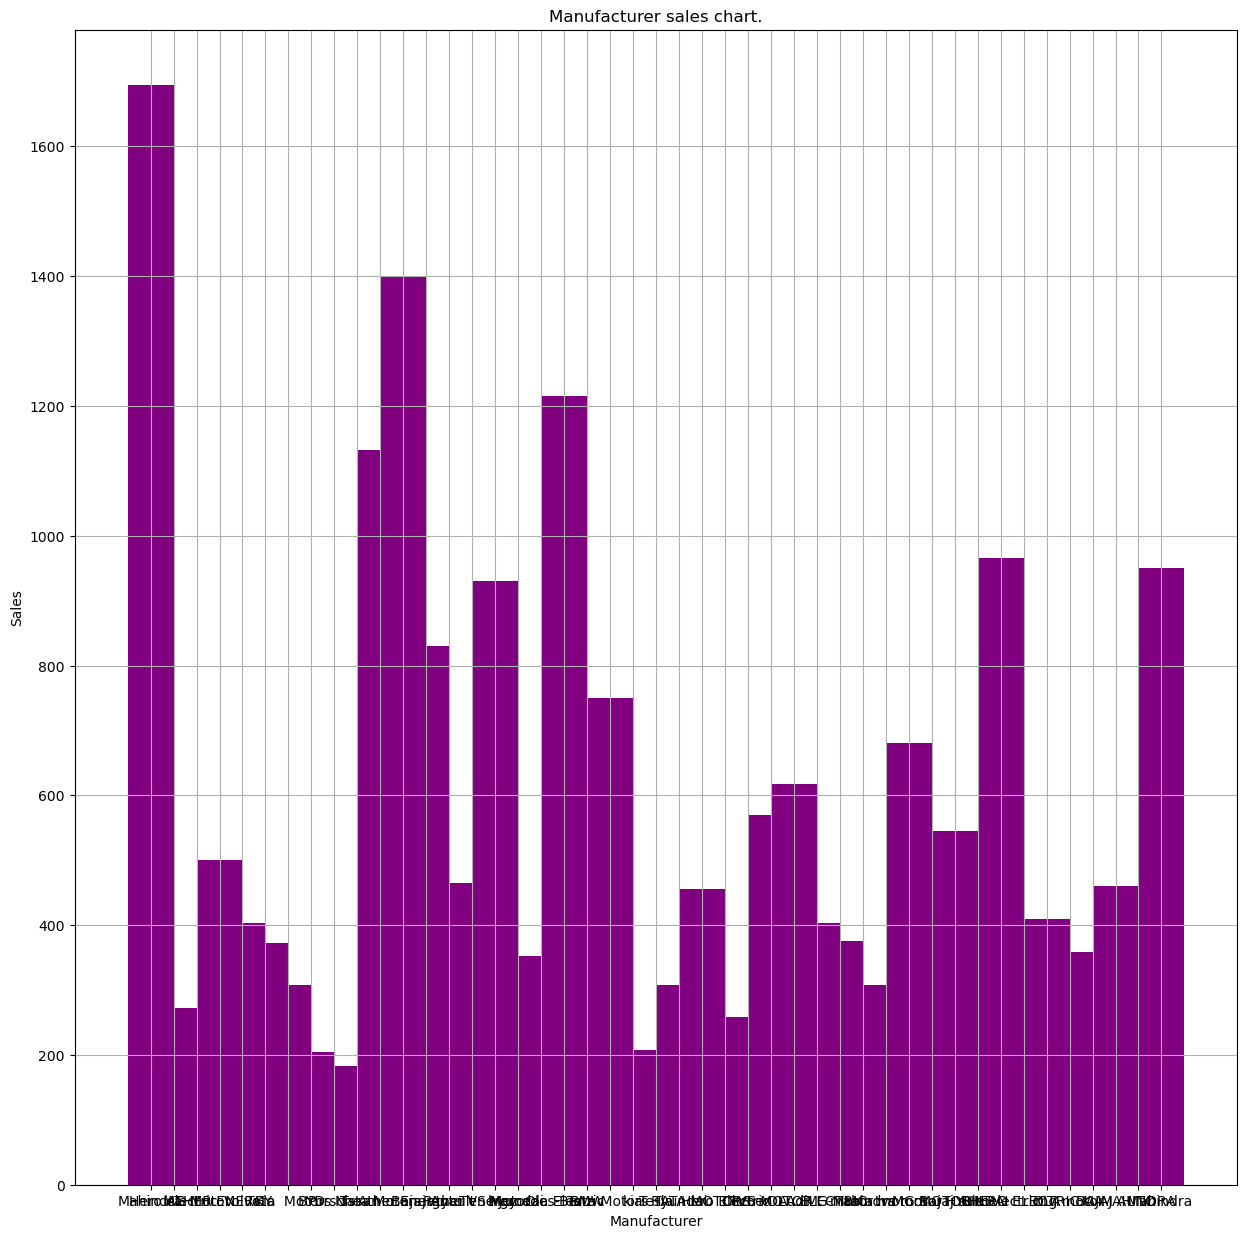

In [27]:
pt.figure(figsize=(15,15))
pt.bar(df['Manufacturer'],df['EV_Sales_Units'],color= 'purple',width=2.0)
pt.xlabel("Manufacturer")
pt.ylabel("Sales")
pt.title("Manufacturer sales chart.")
pt.grid()
pt.show()

In [25]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'], errors='coerce')
pt.figure(figsize=(15,15))
7pt.plot(df['Sale_Date'].dt.month_name(),df['EV_Sales_Units'],color= 'red',marker='*')
pt.xlabel("Electric vehicle unit sales",fontsize=1)
pt.ylabel("Sale_Date")
pt.title("Sales Trend chart.")
pt.grid()
pt.show()

SyntaxError: invalid decimal literal (4253971205.py, line 3)

In [ ]:
import matplotlib.pyplot as plt
df['Vehicle_Type'] = df['Vehicle_Type'].str.strip().str.capitalize()
vehicle_counts = df['Vehicle_Type'].value_counts()
labels = vehicle_counts.index
pt.figure(figsize=(6, 6))
pt.pie(
    vehicle_counts, 
    labels=labels, 
    explode=[0.1,0.0,0.0,0.0,0.0,0.0,0.0],
    autopct='%1.1f%%', # Functional anchor: displays the percentage of each slice automatically
    colors=['pink', 'yellow', 'red', 'green', 'blue', 'orange', 'cyan'][:len(labels)],
    startangle=140
)
pt.title("Types of Vehicles Breakdown", fontsize=14, fontweight='bold')
pt.show()

In [ ]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'], errors='coerce')
df = df.replace(['-', 'unknown', 'Unknown', 'UNKNOWN', ''], np.nan)
string_cols = ['Manufacturer','Model','Vehicle_Type','Market_Segment','State','City','Charging_Type']
for col in string_cols:
    df[col] = df[col].astype('string')
numeric_cols = ['Battery_Capacity_kWh','Driving_Range_km','Vehicle_Price_INR','EV_Sales_Units','Charging_Time_Hours','Dealer_Count']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
pt.hist(df['Battery_Capacity_kWh'],color='orange')
pt.title("Battery Capacity")
pt.show()

In [ ]:
target_manufacturers = ['Tata Motors', 'Mahindra', 'Ola Electric', 'TVS Motor']
hist_data = [
    df[df['Manufacturer'] == brand]['Driving_Range_km'].dropna() 
    for brand in target_manufacturers
]
plt.figure(figsize=(12, 6))
plt.hist(
    hist_data, 
    bins=10, 
    range=(0, 700),  # Corrected range to reflect realistic driving distance km scales
    color=['red', 'yellow', 'green', 'blue'][:len(target_manufacturers)], 
    label=target_manufacturers,
)
plt.xlabel("Driving Range (km)", fontsize=11)
plt.ylabel("Number of EV Models", fontsize=11)
plt.title("Driving Range Distribution by Manufacturer", fontsize=14, fontweight='bold')
plt.legend(title="Manufacturers")  # Displays the color codes
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pt
import seaborn as sns
for col in ['Manufacturer', 'Model', 'Vehicle_Type', 'Market_Segment', 'State', 'City', 'Charging_Type']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()
df = df[(df['Driving_Range_km'] > 0) & (df['Battery_Capacity_kWh'] > 0)]
pt.figure(figsize=(12, 6))
state_sales = df.groupby('State')['EV_Sales_Units'].sum().sort_values(ascending=False)
sns.barplot(x=state_sales.index, y=state_sales.values, palette='viridis')
pt.xticks(rotation=45, ha='right', fontsize=9) # Shrunk label size for scannability
pt.xlabel("State", fontsize=11)
pt.ylabel("Total EV Sales (Units)", fontsize=11)
pt.title("Total Electric Vehicle Sales Units Across States", fontsize=14, fontweight='bold')
pt.grid(axis='y', linestyle='--', alpha=0.5)
pt.tight_layout()
pt.show()

In [ ]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
pt.title("Correlation Matrix of Numeric EV Attributes", fontsize=14, fontweight='bold')
pt.tight_layout()
pt.show()

In [ ]:
pt.figure(figsize=(10, 5))
price_filtered = df[df['Vehicle_Price_INR'] <= 30000000]
sns.boxplot(x=price_filtered['Vehicle_Price_INR'], color='salmon', flierprops={'markerfacecolor':'red', 'marker':'o'})
pt.xlabel("Vehicle Price (INR in Tens of Millions)", fontsize=11)
pt.title("Spread and Distribution of EV Pricing", fontsize=14, fontweight='bold')
pt.grid(axis='x', linestyle='--', alpha=0.5)
pt.show()

In [ ]:
pt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='Battery_Capacity_kWh', 
    y='Driving_Range_km', 
    hue='Market_Segment', 
    palette='Set1', 
    alpha=0.8, 
    s=70
)
pt.xlabel("Battery Capacity (kWh)", fontsize=11)
pt.ylabel("Driving Range (km)", fontsize=11)
pt.title("Relationship: Battery Capacity vs. Driving Range", fontsize=14, fontweight='bold')
pt.legend(title="Market Segment")
pt.grid(True, linestyle='--', alpha=0.5)
pt.show()

In [ ]:
plt.figure(figsize=(8, 6))
numeric_cols = ['Battery_Capacity_kWh', 'Driving_Range_km', 'Vehicle_Price_INR', 'EV_Sales_Units', 'Charging_Time_Hours']
corr_matrix = df[numeric_cols].corr()

In [ ]:
sns.set_theme(style="ticks")
pair_grid = sns.pairplot(df, vars=['Battery_Capacity_kWh', 'Driving_Range_km', 'Vehicle_Price_INR'], 
    hue='Market_Segment', 
    palette='Dark2',
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 's': 40}
)
pair_grid.fig.suptitle("Pair Plot Matrix of Key EV Metrics", y=1.02, fontsize=16, fontweight='bold')
pt.show()